# How often does it pay to go for it on 4th down?
**Project 1 – Applied Probability.** Which rule for when to go for it on 4th down wins the most games?
We estimate probabilities from NFL play-by-play data (2018–2025), simulate whole games as a Markov chain, and compare
strategies with Monte Carlo.

This notebook only **shows** the results. The simulations are run in `compute.ipynb`, which saves `results.json`.

In [1]:
import pandas as pd
import model as M
import plots as P

m = M.estimate(M.load_data())          # probabilities from the data (a few seconds)
res = M.load_results("results.json")   # simulation results from compute.ipynb
best = M.build(res["best"], res["fg_range"])
print(f"Best strategy: {res['best_name']}  (field goals up to {res['best_k']} yards)")
res["final"].loc[[res["best_name"]], ["p̂", "diff (pp)", "diff lower", "diff upper"]].round(3)

Best strategy: ≤5 yd & pos ≤80 + no man's land 35–50 (≤6 yd) + trailing (≤2 drives) + score-changing FG (≤2 drives) + leading late: no go at pos ≥50 (≤2 drives) | else kick  (field goals up to 57 yards)


,p̂,diff (pp),diff lower,diff upper
≤5 yd & pos ≤80 + no man's land 35–50 (≤6 yd) + trailing (≤2 drives) + score-changing FG (≤2 drives) + leading late: no go at pos ≥50 (≤2 drives) | else kick,0.542,4.008,3.428,4.588


## 1. Probabilities from the data
**Yards per play.** Yards gained $Y$ is skewed: a point mass at 0 (mostly incomplete passes) and a long right tail.
The simulator stores every real play per (down, yards to go) and **samples** from it; 3rd and 4th down are pooled.

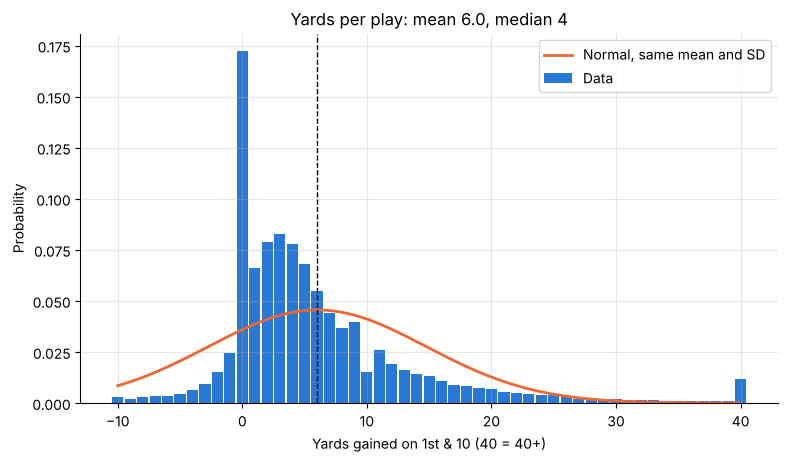

In [2]:
P.yards_per_play(m)

**Probability of a 1st down**, $p(d) = P(\text{1st down} \mid d)$: a proportion per $d$, standard error $\sqrt{\hat p(1-\hat p)/n} < 0.01$.

In [3]:
m["p_d"].loc[1:10].T.round(3)

ydstogo,1,2,3,4,5,6,7,8,9,10
mean,0.7,0.576,0.529,0.488,0.434,0.429,0.384,0.355,0.305,0.294
count,5641.0,3456.000,3178.000,3034.000,3092.000,2891.000,2731.000,2459.000,2079.000,2588.000


**Field goals.** $p_{FG}(x)$ comes from a **logistic regression** $p(x) = 1/(1+e^{-(\beta_0+\beta_1 x)})$,
fitted by maximum likelihood to every kick ($x \approx pos + 18$). The dots show the raw make rate per distance.

**Punts** are drawn only from real punts kicked within ±5 yards of the same spot: near midfield punters aim to
pin the opponent deep rather than kick far, so a punt from the 40 rarely ends in a touchback.

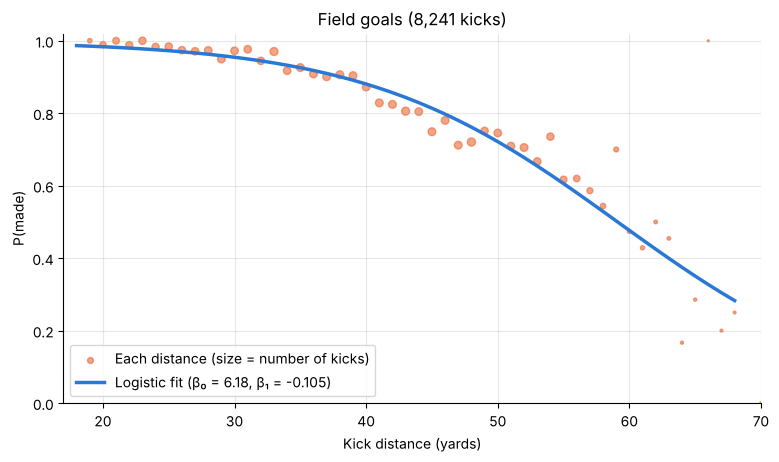

In [4]:
P.field_goals(m)

**Real coaches** (strategy 1, and always the opponent): $P(\text{go} \mid \text{yards to go, pos})$ per cell.
Coaches almost always go on 4th & 1 around midfield, but rarely on their own half.

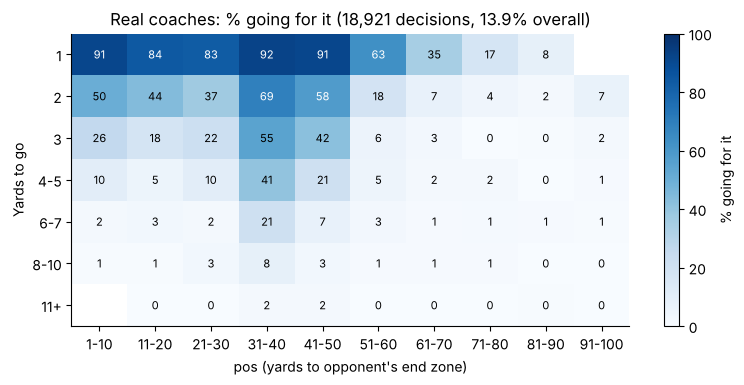

In [5]:
P.coach_go_rates(m)

## 2. Does the simulator work?
A drive is a Markov chain on (down, yards to go, pos). A game is 11 drives per team, no clock.
**Coach vs coach** should give 50% (test of $H_0: p = 0.5$), and simulated $p(d)$ and drive outcomes should match the data.

Coach vs coach: p̂ = 0.4989 [0.4946, 0.5032], p-value = 0.61


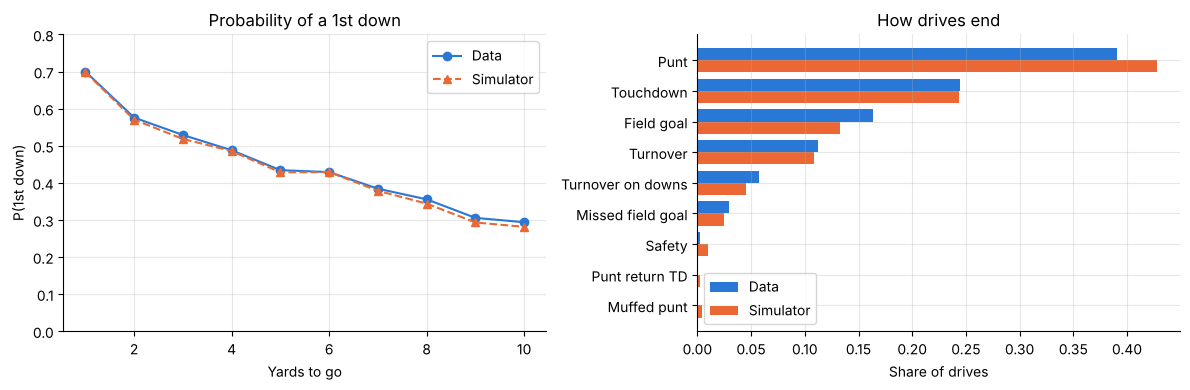

In [6]:
p, lo, hi, pval = res["coach_vs_coach"]
print(f"Coach vs coach: p̂ = {p:.4f} [{lo:.4f}, {hi:.4f}], p-value = {pval:.2f}")
P.validation(res)

The p-value is far from significant, so the simulator has no built-in bias. A few more punts in the simulator,
because real drives also end at halftime, which we don't model.

## 3. Step 1: each strategy on its own
Each game is a Bernoulli trial (win 1, tie ½, loss 0). Game $i$ uses the same random numbers for every strategy,
so differences are **paired**: $D_i = X_i^A - X_i^B$, 95% CI by the CLT.

**How far should we try field goals?**

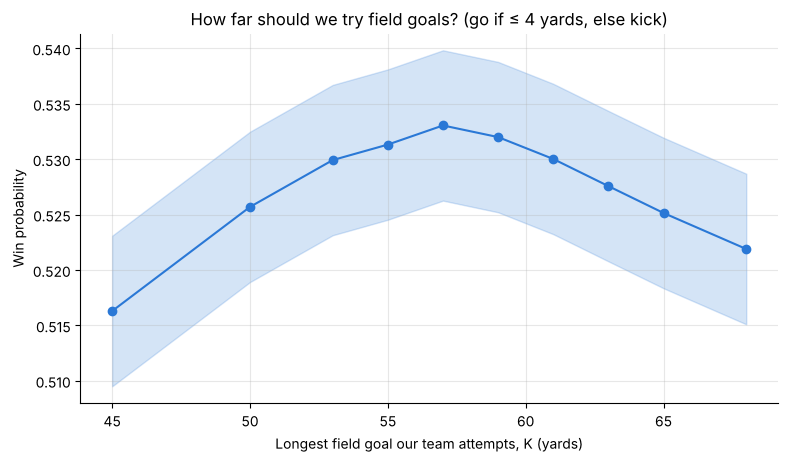

Best K = 57 yards, P(made) there = 55%


In [7]:
P.fg_sweep(res)
print(f"Best K = {res['best_k']} yards, P(made) there = {m['p_fg'][res['fg_range']]:.0%}")

Trying longer field goals helps up to about 57 yards. Beyond that, a punt that pins the opponent deep is worth more
than the long kick (the curve is flat between 55 and 61 yards, so the exact limit hardly matters).

**Aggressiveness:** going for it at random (orange) never beats the coaches. Going for it on short yardage (blue) does:
**where** you go for it matters, not how often.

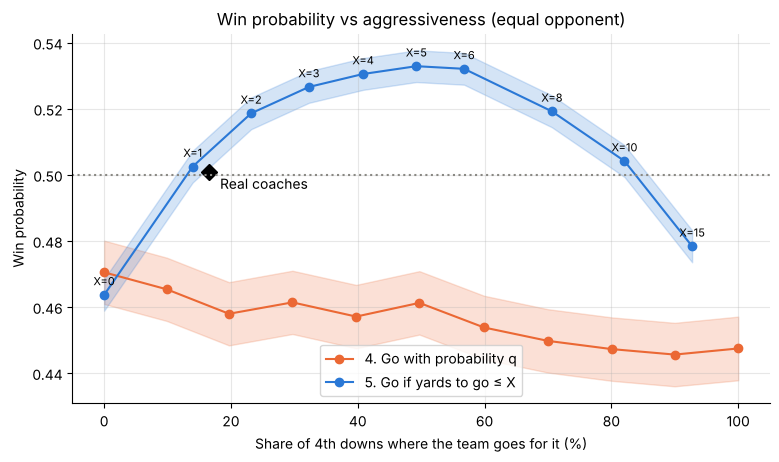

In [8]:
P.aggressiveness(res)

**Short and close** (go if yards to go ≤ X and pos ≤ Y, X = 1–8, Y = 10–100 in 10-yard steps; Y = 100 is "go if ≤ X"
anywhere), 100,000 paired games per cell. Boxed: cells **not significantly worse than the best cell**. Seven cells tie:
X = 6–7 with Y = 70/80–100. So with enough games the ranking is clear about *how many yards* (6–7) but not about *how deep*:
stopping at our own 20–30 or going anywhere are statistically the same, because deep 4th downs with 4+ yards to go are rare.
Restricting attempts to near the goal (small Y) clearly hurts. The 10 best cells go into the combination search.

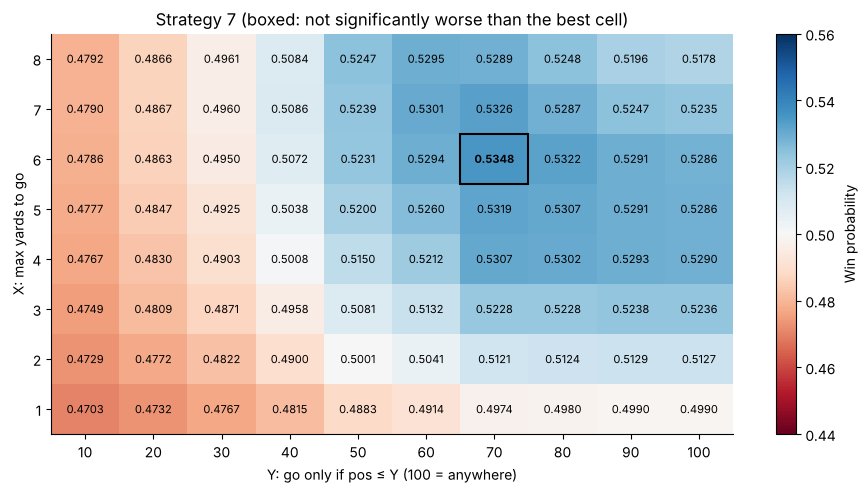

In [9]:
P.short_and_close(res)

**No man's land:** just outside field-goal range (about pos 35–55) a punt gains little and a field goal is unlikely.
On top of short yardage, also going for it there with ≤ 10 yards to go adds at most about +0.3 pp (the heatmap is
nearly flat, so the exact range is within noise). The 10 best ranges (boxed) all go into the combination search.
Without a yards-to-go limit the rule would also go on 4th & 15, which converts only about 14% of the time.

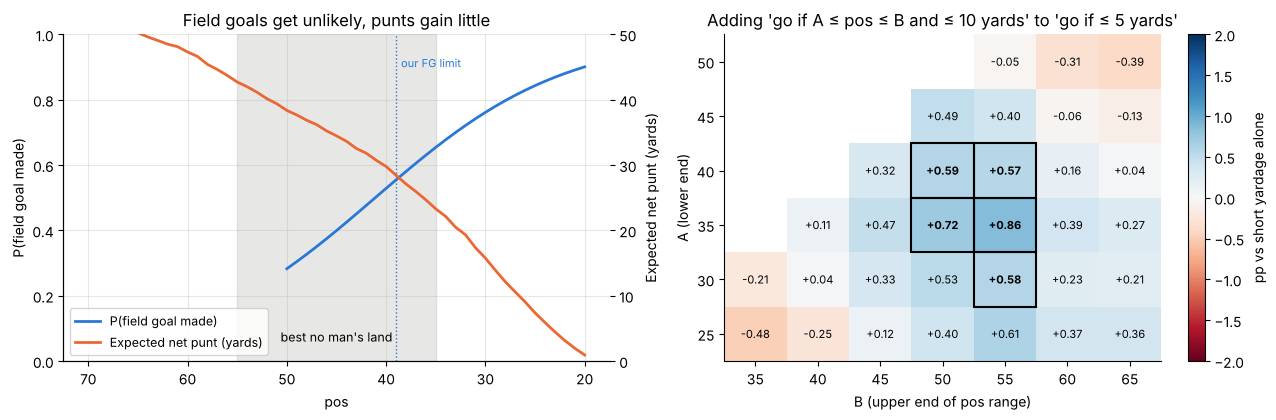

In [10]:
P.no_mans_land(m, res)

**Trailing late** (go when behind with ≤ N drives left), win probability:

In [11]:
res["sweep_n"].T.round(3)

,1,2,3,4,6,8,12
p̂,0.481,0.486,0.491,0.499,0.497,0.504,0.503


**All single strategies** (30,000 paired games). Only the yards-to-go rules beat the coaches by more than about 1 pp on their own.

**Score-changing field goal** (rule 12: with ≤ 3 drives left and in field-goal range, always kick when the field goal changes
the number of scores between the teams: up 6–8 → 9+, or down 9–11 → within 8) makes no measurable difference: the situation is rare.

**Leading late** (rule 13, new: when ahead with ≤ 2 drives left, never go for it in our own half) adds about +0.4 pp on top of
"go if ≤ 6 yards" (+4.2 vs +3.8): a failed attempt there hands the opponent a short field for the winning score. On top of the
coaches it changes nothing, because coaches rarely go for it there anyway.

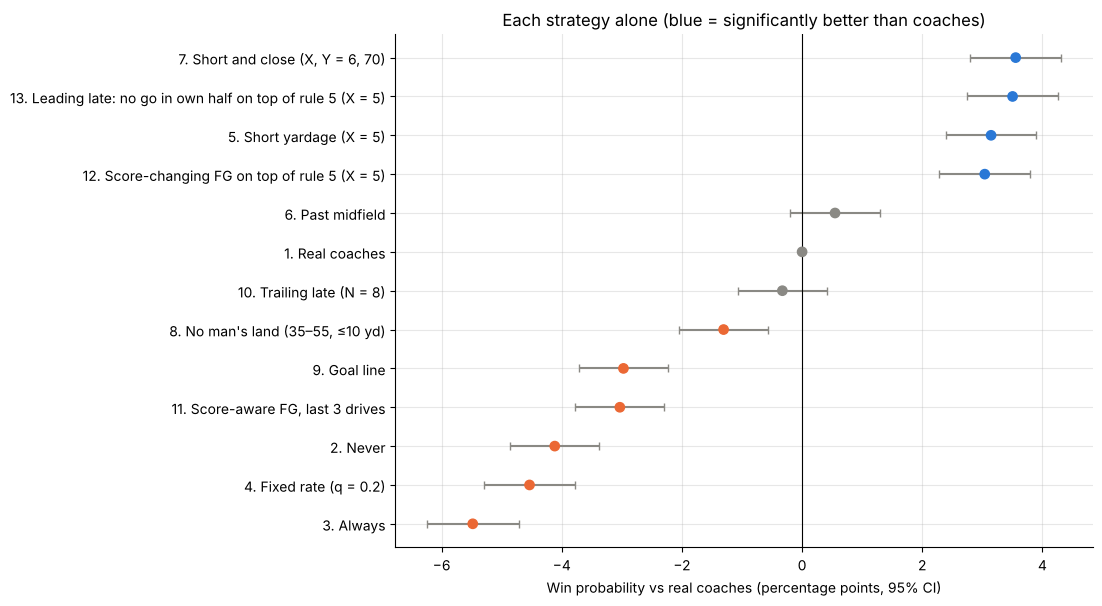

,p̂,diff (pp),diff lower,diff upper,go %
1. Real coaches,0.502,0.000,0.000,0.000,16.475
2. Never,0.461,-4.117,-4.855,-3.378,0.000
3. Always,0.447,-5.482,-6.243,-4.720,100.000
4. Fixed rate (q = 0.2),0.457,-4.537,-5.294,-3.780,19.918
5. Short yardage (X = 5),0.534,3.145,2.390,3.900,49.395
6. Past midfield,0.508,0.548,-0.206,1.302,46.108
"7. Short and close (X, Y = 6, 70)",0.538,3.555,2.800,4.310,49.420
"8. No man's land (35–55, ≤10 yd)",0.489,-1.307,-2.054,-0.560,21.535
9. Goal line,0.472,-2.973,-3.712,-2.235,2.964
10. Trailing late (N = 8),0.499,-0.328,-1.072,0.415,41.670


In [12]:
P.diffs(res["singles"], "Each strategy alone (blue = significantly better than coaches)")
res["singles"].round(3)

## 4. Step 2: the best combination
**Successive halving:** play all candidates on 500 games, keep the best quarter, play the survivors on 4× more games, repeat
(500 → 2,000 → 8,000 → 32,000 games). Candidates: one of the 10 best strategy-7 cells, one of the 10 best no man's land ranges
(≤ 6 or ≤ 10 yards), goal line, trailing late (2, 3 or 6 drives) and the score-changing field goal (1, 2 or 3 drives);
otherwise kick. 7,392 candidates.

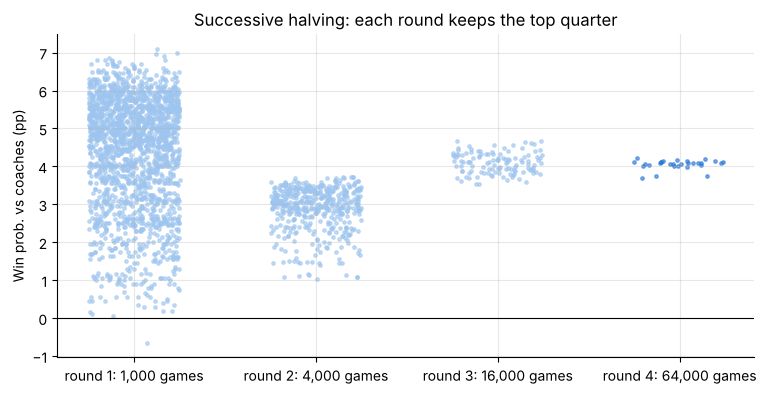

In [13]:
P.halving(res)

**Which rules matter?** Regression of each candidate's gain on 0/1 indicators of its rules:
$\beta_r$ = average change in win probability from adding rule $r$.

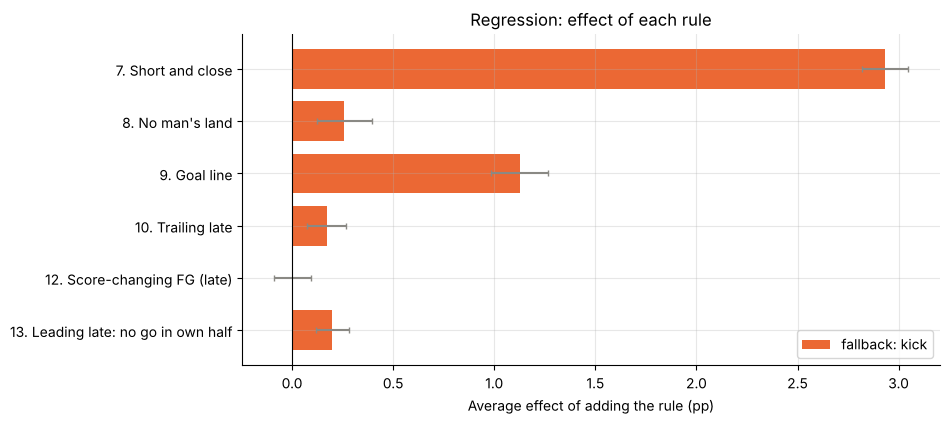

In [14]:
P.effects(res)

**Final check** (50,000 paired games, fresh random numbers): the top 5, the best single rule and the coaches. The best one (orange) is our strategy.

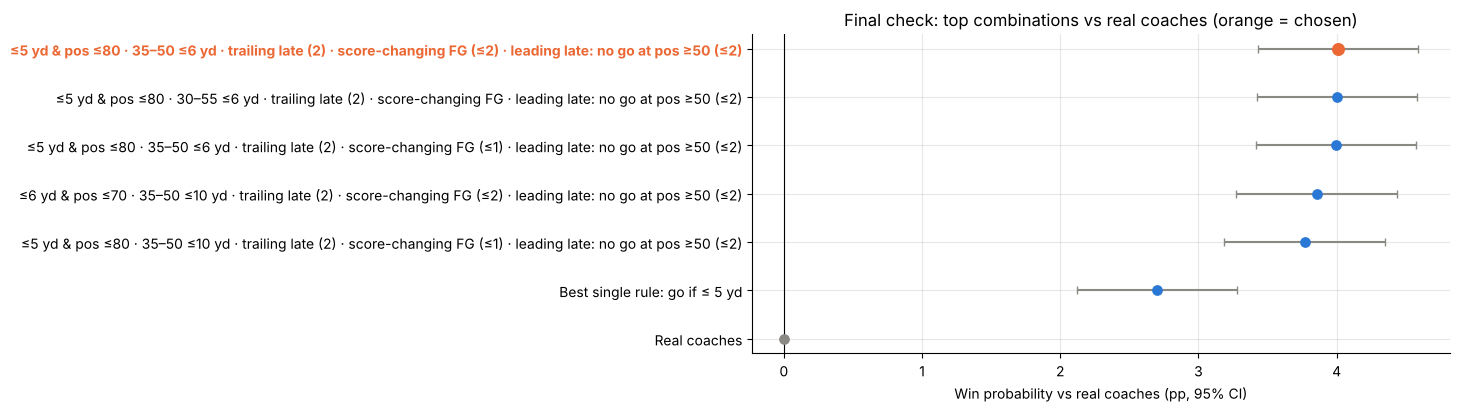

Best combination − best single rule = 1.31 pp [1.01, 1.61]


In [15]:
P.final_check(res)
print("Best combination − best single rule = {:.2f} pp [{:.2f}, {:.2f}]".format(*res["best_vs_single"]))

**Why does field position matter so little?** Even deep in our own half a failed attempt costs less than it looks: the opponent's
next drive scores a touchdown far more often than after a punt, but 4th & 1–2 converts often enough to outweigh that.
Net points over the rest of our drive and the opponent's next drive (`deep_tradeoff.py`, 20,000 simulations per row):

In [16]:
pd.read_csv("deep_tradeoff.csv").set_index(["our own", "4th &"]).round(2)

P(convert)  opp TD after failed go  opp TD after punt  \
our own 4th &                                                          
1       1            0.69                    0.94               0.43   
        2            0.57                    0.94               0.41   
        4            0.49                    0.93               0.42   
5       1            0.70                    0.87               0.39   
        2            0.58                    0.86               0.39   
        4            0.49                    0.84               0.39   
10      1            0.69                    0.73               0.35   
        2            0.58                    0.74               0.35   
        4            0.48                    0.74               0.35   
20      1            0.69                    0.61               0.29   
        2            0.57                    0.61               0.29   
        4            0.48                    0.61               0.29   
30      1            0.70                    0.52               0.24   
        2            0.58                    0.52               0.24   
        4            0.49                    0.53               0.23   

               opp score after failed go  opp score after punt  net pts: go  \
our own 4th &                                                                 
1       1                           0.97                  0.66        -2.52   
        2                           0.97                  0.65        -3.00   
        4                           0.97                  0.66        -3.37   
5       1                           0.95                  0.60        -2.48   
        2                           0.95                  0.61        -2.91   
        4                           0.95                  0.60        -3.18   
10      1                           0.93                  0.54        -2.19   
        2                           0.93                  0.55        -2.65   
        4                           0.93                  0.55        -3.07   
20      1                           0.88                  0.45        -1.63   
        2                           0.89                  0.45        -2.15   
        4                           0.89                  0.44        -2.48   
30      1                           0.83                  0.36        -1.05   
        2                           0.83                  0.37        -1.57   
        4                           0.83                  0.36        -1.95   

               net pts: punt  go − punt (pts)  
our own 4th &                                  
1       1              -3.64             1.12  
        2              -3.57             0.57  
        4              -3.63             0.26  
5       1              -3.35             0.87  
        2              -3.35             0.43  
        4              -3.35             0.17  
10      1              -3.00             0.81  
        2              -3.04             0.38  
        4              -3.01            -0.06  
20      1              -2.51             0.88  
        2              -2.49             0.34  
        4              -2.46            -0.02  
30      1              -2.03             0.98  
        2              -2.03             0.46  
        4              -1.99             0.04

## 5. Step 3: opponent strength
Strong / weak opponent = plays only from the top / bottom third of teams by EPA per play.
The stronger the opponent, the more aggression pays.

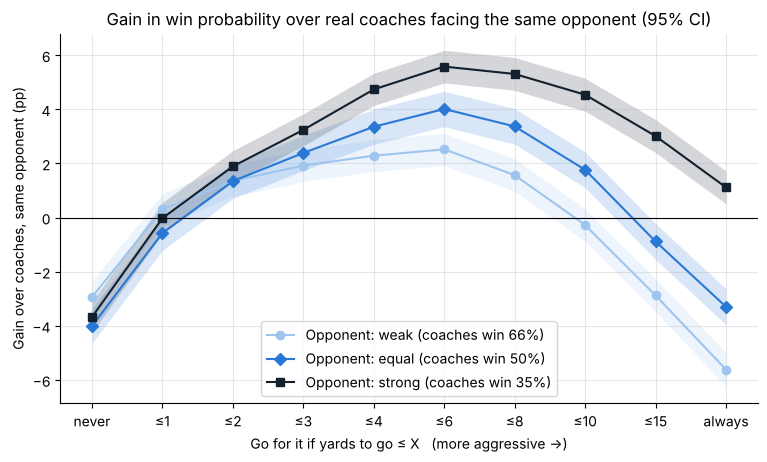

,weak,equal,strong
best single (≤6 yd),3.0,4.5,5.4
best combination,3.7,4.9,5.7


In [17]:
P.opponents(res)
res["opp_res"].round(1)

## 6. The handbook
What the best strategy does on every 4th down in a normal situation (tied game, not late), next to what coaches usually do.

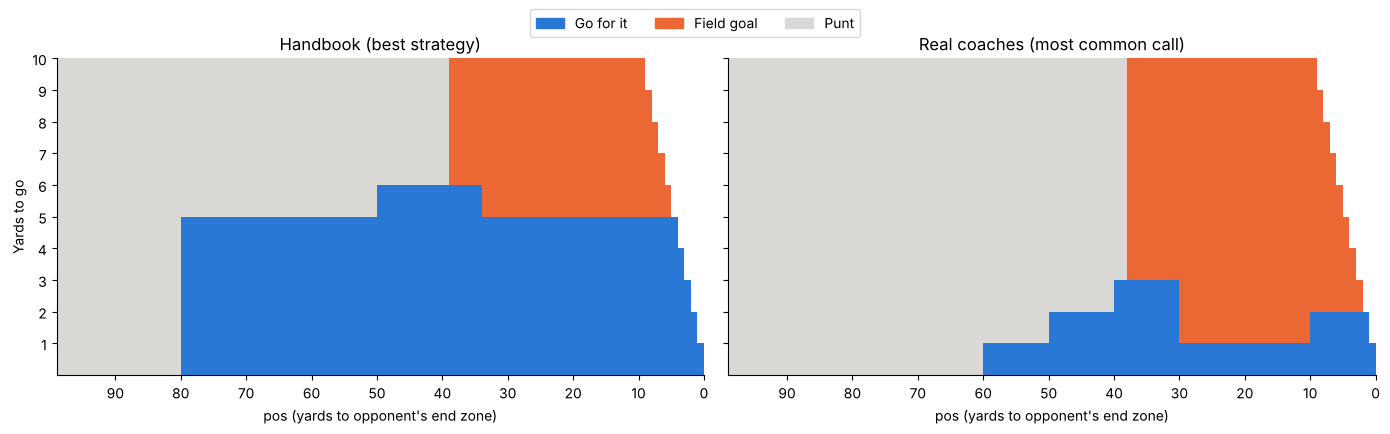

In [18]:
hb = M.handbook(m, best)
P.handbook_map(hb)

**The handbook in one table:** in each zone, go for it with this many yards to go or fewer.

In [19]:
M.go_thresholds(hb)

,go if yards to go ≤,otherwise
pos (yards to end zone),,
1-10,5,fg
11-20,5,fg
21-30,5,fg
31-40,6,fg/punt
41-50,6,punt
51-60,5,punt
61-70,5,punt
71-80,5,punt
81-90,never,punt


**Look up any situation** (change the numbers):

In [20]:
hb.query("togo == 4 and pos == 55").round(2)

,togo,pos,call,P(1st down),FG distance,P(FG good),coaches go %,coaches usually
345,4,55,go,0.49,73,0.0,5.04,punt


## 7. Conclusions
1. Both extremes lose, and so does random aggressiveness: **where** you go for it matters, not how often.
2. Short yardage is the main driver: "go if ≤ 6 yards to go" alone gives about +4.0 pp.
3. Field goals pay up to about 57 yards; beyond that, punting and pinning the opponent deep is worth more.
4. The best combination (≤ 5 yards except inside our own 5, ≤ 6 yards in no man's land 35–55, trailing late, and a
   score-changing field goal on the last drive) wins about 54.7%, +4.5 pp over the coaches. That is only +0.2 pp
   [−0.1, 0.5] more than the best single rule: combining rules adds very little.
5. Field position barely matters: limiting attempts to outside our own 5–20 is within noise of going anywhere, because
   4th & 1–2 converts often enough to outweigh the cost of a failure deep in our own half.
6. The stronger the opponent, the more aggression pays.
7. Late-game score rules (trailing late, score-changing field goal) are rare situations and change little.

**Caveats:** no clock or penalties (so running out the clock with a lead is not modelled); the opponent does not adapt; 4th downs modelled with 3rd-down plays; opponent
strength only affects its offense. Results compare strategies; they are not exact win probabilities.